# ➡️ Lesson 03 · Forward Propagation & Loss Functions

*“You can't improve what you can't measure: the loss function is the network's conscience.”*

| ⏱ Time | 🎚 Level | 🗓 Suggested day | 📚 You should know |
|:--|:--|:--|:--|
| ~80 min | 🟡 Intermediate | Day 3 | Lessons 01–02 |

## 🎯 Learning objectives
By the end of this lesson you will be able to:

- Carry out **forward propagation** by hand on a small network and confirm it in code
- Explain what a **loss function** is and why we need a *differentiable* one
- Implement and choose between **MSE, MAE, Huber, binary cross-entropy and categorical cross-entropy**
- Understand cross-entropy as *surprise*, and why MSE is a poor choice for classification
- Use the **"initial loss ≈ ln(k)"** sanity check that catches many bugs before training even starts
- Distinguish a **loss** (what we optimise) from a **metric** (what we report)

## 🗺 Roadmap
1. Forward propagation: a full worked example
2. Loss: turning 'wrong' into a number
3. Regression losses
4. Classification losses & cross-entropy
5. Why not MSE for classification?
6. A first look at the loss landscape
7. Loss vs metric
8. Problems

## ⚙️ Setup
Run this cell first. It loads our libraries and the course helper module (`utils/dlcourse.py`).

In [1]:
import sys; sys.path.append("..")          # so we can import the course helper library
import numpy as np
import matplotlib.pyplot as plt
from utils import dlcourse as dl

dl.set_seed(42)                          # reproducible randomness
%matplotlib inline

---
## ➡️ 1. Forward propagation: a complete worked example

**Forward propagation** (the *forward pass*) is simply: *push the input through the network, layer by layer, until you get a prediction.*
No learning happens here: it's the network *answering a question*.

**Story.** An irrigation advisor takes two readings from a maize plot (`x₁` = soil dryness, `x₂` = heat index) and outputs the *probability that the plot needs watering today*.

Our tiny network: **2 inputs → 2 hidden (ReLU) → 1 output (sigmoid)**. The input is $x=(1, 2)$, and the true answer is **yes** ($y=1$).

| Parameter | Value |
|:--|:--|
| $W^{[1]}$ (2×2) | $\begin{bmatrix}0.5 & -0.4\\ 0.3 & 0.8\end{bmatrix}$ |
| $b^{[1]}$ | $(0.1,\ -0.2)$ |
| $W^{[2]}$ (2×1) | $\begin{bmatrix}0.7\\ -0.6\end{bmatrix}$ |
| $b^{[2]}$ | $0.05$ |

**Step 1: hidden pre-activation** $z^{[1]} = xW^{[1]}+b^{[1]}$:

* $z^{[1]}_1 = 1(0.5) + 2(0.3) + 0.1 = 1.2$
* $z^{[1]}_2 = 1(-0.4) + 2(0.8) - 0.2 = 1.0$

**Step 2: hidden activation** (ReLU): $h = (\max(0,1.2),\max(0,1.0)) = (1.2,\ 1.0)$

**Step 3: output pre-activation**: $z^{[2]} = 1.2(0.7) + 1.0(-0.6) + 0.05 = 0.84 - 0.60 + 0.05 = 0.29$

**Step 4: output activation** (sigmoid): $\hat y = \sigma(0.29) = \dfrac{1}{1+e^{-0.29}} \approx 0.572$

The network says "57 % chance it needs water". The truth is *yes*, so it's right-ish but not confident. **How wrong is it?** That's the loss's job. Let's verify every number in code:

In [2]:
sigmoid = lambda z: 1 / (1 + np.exp(-z))
x  = np.array([[1., 2.]])
W1 = np.array([[0.5, -0.4], [0.3, 0.8]]); b1 = np.array([0.1, -0.2])
W2 = np.array([[0.7], [-0.6]]);            b2 = np.array([0.05])

z1 = x @ W1 + b1;  print("z1 =", z1)
h  = np.maximum(0, z1);  print("h  =", h)
z2 = h @ W2 + b2;  print("z2 =", z2)
y_hat = sigmoid(z2); print("ŷ  =", y_hat.round(4))

y = 1.0
loss = -(y * np.log(y_hat) + (1 - y) * np.log(1 - y_hat))
print("binary cross-entropy loss =", loss.round(4))

z1 = [[1.2 1. ]]
h  = [[1.2 1. ]]
z2 = [[0.29]]
ŷ  = [[0.572]]
binary cross-entropy loss = [[0.5586]]


> 🛠 **Pro tip**: In real code the forward pass is exactly this: a sequence of `Z = A @ W + b; A = activation(Z)`. Frameworks *cache* each `Z` and `A` because backpropagation (Lesson 04) will need them again.

---
## 📏 2. Loss: turning “how wrong?” into a number

A **loss function** $\mathcal{L}(\hat y, y)$ compares a prediction to the truth and returns **one non-negative number: 0 = perfect, bigger = worse.**
The average loss over the training set is what training tries to minimise.

A good loss must be:
1. **Meaningful**: lower loss ⇒ better predictions for *your* problem.
2. **Differentiable** (almost everywhere), so gradient descent can tell us which way to move the weights.

That second point is why we *train* on cross-entropy but *report* accuracy: accuracy jumps in steps (a prediction is either right or wrong), giving gradient descent nothing to grip.

| Task | Typical output layer | Typical loss |
|:--|:--|:--|
| Regression (price, yield) | Linear (no activation) | **MSE**, **MAE**, **Huber** |
| Binary classification (diseased / healthy) | 1 neuron + sigmoid | **Binary cross-entropy (BCE)** |
| Multi-class (digit 0–9) | k neurons + softmax | **Categorical cross-entropy (CE)** |
| Multi-label (a leaf can have several diseases) | k neurons + sigmoid each | BCE per label |

---
## 📈 3. Regression losses

$$\text{MSE}=\frac1m\sum (\hat y_i-y_i)^2 \qquad \text{MAE}=\frac1m\sum |\hat y_i-y_i| \qquad
\text{Huber}_\delta(e)=\begin{cases}\tfrac12e^2 & |e|\le\delta\\ \delta(|e|-\tfrac12\delta) & |e|>\delta\end{cases}$$

* **MSE** squares errors → *hates big mistakes*, very sensitive to outliers, smooth gradient (∝ error).
* **MAE** is robust to outliers but its gradient has constant size (jumpy near 0).
* **Huber** = quadratic near zero, linear far away: the best of both.

Let's try them on a real problem: a "naive" forecaster that predicts *this week's maize price = last week's price*.

MAE  =    123.4 KES      (typical error, same units as price)
RMSE =    165.4 KES      (sqrt of MSE; penalises big misses)
MSE  =    27359 KES²     (hard to interpret; squared units!)


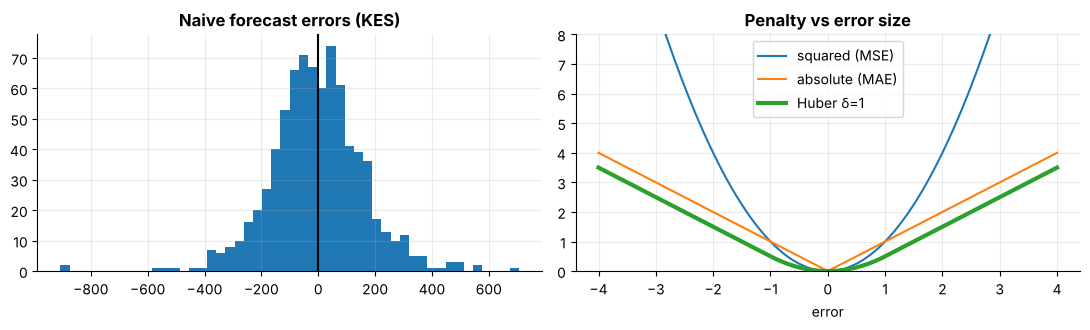

In [3]:
prices = dl.load_prices()
y_true = prices.price_kes_90kg.values[1:].astype(float)
y_pred = prices.price_kes_90kg.values[:-1].astype(float)        # naive: yesterday's value
err = y_pred - y_true

mse, mae = np.mean(err ** 2), np.mean(np.abs(err))
print(f"MAE  = {mae:8.1f} KES      (typical error, same units as price)")
print(f"RMSE = {np.sqrt(mse):8.1f} KES      (sqrt of MSE; penalises big misses)")
print(f"MSE  = {mse:8.0f} KES²     (hard to interpret; squared units!)")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].hist(err, bins=50); ax[0].set_title("Naive forecast errors (KES)"); ax[0].axvline(0, c="k")
e = np.linspace(-4, 4, 200); delta = 1
ax[1].plot(e, e**2, label="squared (MSE)"); ax[1].plot(e, np.abs(e), label="absolute (MAE)")
ax[1].plot(e, np.where(np.abs(e) <= delta, .5 * e**2, delta * (np.abs(e) - .5 * delta)), label="Huber δ=1", lw=3)
ax[1].set_ylim(0, 8); ax[1].legend(); ax[1].set_title("Penalty vs error size"); ax[1].set_xlabel("error")
plt.tight_layout(); plt.show()

> 🇰🇪 **In the field**: Which loss would you choose for a price model used by a farmer deciding when to sell? A single drought-week spike of 3,000 KES shouldn't dominate training *but* shouldn't be ignored either. Huber is a natural compromise, and a good reminder that **the loss encodes what you care about.**

---
## 🎯 4. Classification losses & cross-entropy

A classifier outputs **probabilities**. If the true class is "rust" and the model says *p(rust) = 0.9*, we're happy; if it says *0.01*, we're furious. The loss should
reflect that, and **cross-entropy** does with a beautiful idea: *surprise*.

> 💡 **Big idea: Loss = surprise.** If the model assigned probability $p$ to what actually happened, its surprise is $-\ln p$.
> Certain and right ($p=1$) → surprise 0. Hopelessly wrong ($p\to0$) → surprise $\to\infty$.

**Binary cross-entropy** (true label $y\in\{0,1\}$, predicted probability $\hat p$ of class 1):
$$\text{BCE}=-\big[\,y\ln\hat p+(1-y)\ln(1-\hat p)\,\big]$$

**Categorical cross-entropy** (true class $c$, predicted distribution $\hat{\mathbf p}$): simply $\;-\ln \hat p_c$: *the log-probability the model gave the correct class.*

**Worked example.** Three classes, true class is 0 (index 0). Model A outputs $[0.7,0.2,0.1]$, Model B outputs $[0.1,0.2,0.7]$:

* Model A: $-\ln 0.7 = 0.357$   ← mildly surprised
* Model B: $-\ln 0.1 = 2.303$   ← very surprised

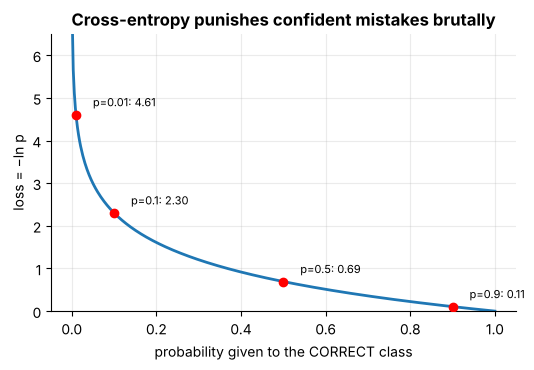

In [4]:
p = np.linspace(0.001, 1, 400)
plt.figure(figsize=(6, 3.6)); plt.plot(p, -np.log(p), lw=2)
for pp in [0.9, 0.5, 0.1, 0.01]:
    plt.scatter(pp, -np.log(pp), c="r", zorder=3); plt.annotate(f"p={pp}: {-np.log(pp):.2f}", (pp, -np.log(pp)), xytext=(pp + .04, -np.log(pp) + .2), fontsize=8)
plt.xlabel("probability given to the CORRECT class"); plt.ylabel("loss = −ln p"); plt.title("Cross-entropy punishes confident mistakes brutally"); plt.ylim(0, 6.5)
plt.show()

#### From logits to loss: the numerically safe way
Networks output raw **logits** $z$. Softmax then log can overflow/underflow. Combine them: $\ln\text{softmax}(z)_c = z_c - \ln\sum_j e^{z_j}$, and compute the log-sum-exp stably:
$$\text{CE}(z, c) = \ln\sum_j e^{z_j} - z_c = \Big(m+\ln\sum_j e^{z_j-m}\Big) - z_c,\qquad m=\max_j z_j$$

In [5]:
def cross_entropy_from_logits(logits, y):
    """logits: (m, k) raw scores; y: (m,) integer class labels. Returns the mean loss."""
    m = logits.max(axis=1, keepdims=True)
    log_sum_exp = m.squeeze(1) + np.log(np.exp(logits - m).sum(axis=1))
    correct_logit = logits[np.arange(len(y)), y]
    return np.mean(log_sum_exp - correct_logit)

logits = np.array([[2.0, 1.0, 0.1], [0.1, 0.2, 3.0]])
y = np.array([0, 2])
print("CE loss:", cross_entropy_from_logits(logits, y).round(4))

# Cross-check against the textbook formula  −mean(ln p_correct)
p = np.exp(logits) / np.exp(logits).sum(1, keepdims=True)
print("textbook :", (-np.log(p[np.arange(2), y])).mean().round(4))
print("huge logits stay finite:", cross_entropy_from_logits(np.array([[1000., 0., -1000.]]), np.array([0])))

CE loss: 0.2633
textbook : 0.2633
huge logits stay finite: 0.0


> ⚠️ **Watch out**: PyTorch's `nn.CrossEntropyLoss` expects **raw logits** (no softmax!) and **integer class labels** (not one-hot). Applying softmax first, then CrossEntropyLoss, is one of the most common beginner bugs: it still trains, just worse. You'll see it in Lesson 05.

#### The free sanity check
Before training, a network with small random weights outputs roughly equal logits → probability ≈ $1/k$ for every class → expected loss ≈ $-\ln(1/k)=\ln k$.
For 10 classes: **ln 10 ≈ 2.303**. If your first loss is 50 or 0.01: *something is wrong* (bad labels, wrong loss, forgotten normalisation). Check this *every* time. It takes five seconds and saves hours.

In [6]:
print("Expected initial loss for k classes:  ln k")
for k in [2, 5, 10, 100]:
    print(f"  k={k:3d} → {np.log(k):.3f}")

Expected initial loss for k classes:  ln k
  k=  2 → 0.693
  k=  5 → 1.609
  k= 10 → 2.303
  k=100 → 4.605


---
## 🤔 5. Why not use MSE for classification?

You *could* treat probabilities as numbers and use MSE. It's a bad idea, and the reason is subtle and beautiful.
For a sigmoid output $a=\sigma(z)$ with true label $y=1$, the gradient of the loss with respect to the pre-activation $z$ is:

* **MSE:** $\;(a-y)\cdot a(1-a)$: the extra factor $a(1-a)$ → **0** when the neuron is saturated.
* **BCE:** $\;(a-y)$: the sigmoid's slope *cancels perfectly*.

So with MSE, a neuron that is **confidently wrong** (z = −6 when the answer is 1) barely learns; with BCE it gets a strong correction. Look:

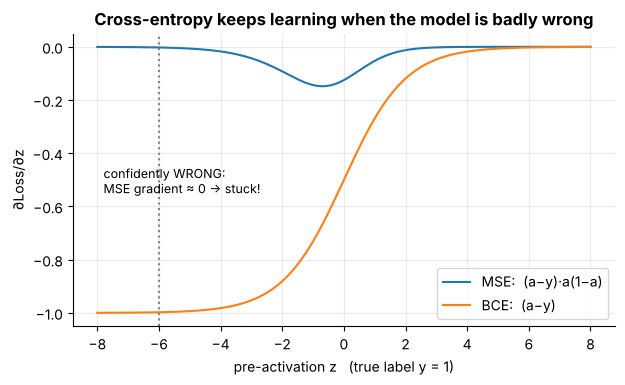

In [7]:
sigmoid = lambda z: 1 / (1 + np.exp(-z))
z = np.linspace(-8, 8, 300); a = sigmoid(z); y = 1.0
grad_mse = (a - y) * a * (1 - a)
grad_bce = (a - y)
plt.figure(figsize=(7, 3.8))
plt.plot(z, grad_mse, label="MSE:  (a−y)·a(1−a)"); plt.plot(z, grad_bce, label="BCE:  (a−y)")
plt.axvline(-6, c="gray", ls=":"); plt.annotate("confidently WRONG:\nMSE gradient ≈ 0 → stuck!", (-6, -.05), xytext=(-7.8, -.55), fontsize=9)
plt.xlabel("pre-activation z   (true label y = 1)"); plt.ylabel("∂Loss/∂z"); plt.legend(); plt.title("Cross-entropy keeps learning when the model is badly wrong")
plt.show()

---
## 🏔 6. A first look at the loss landscape

Every choice of weights gives a loss value, so the loss is a *surface over weight-space*: hills where the model is bad, valleys where it's good.
**Training = walking downhill.** For the simplest model $\hat y = w x + b$ with MSE, we can draw the whole landscape:

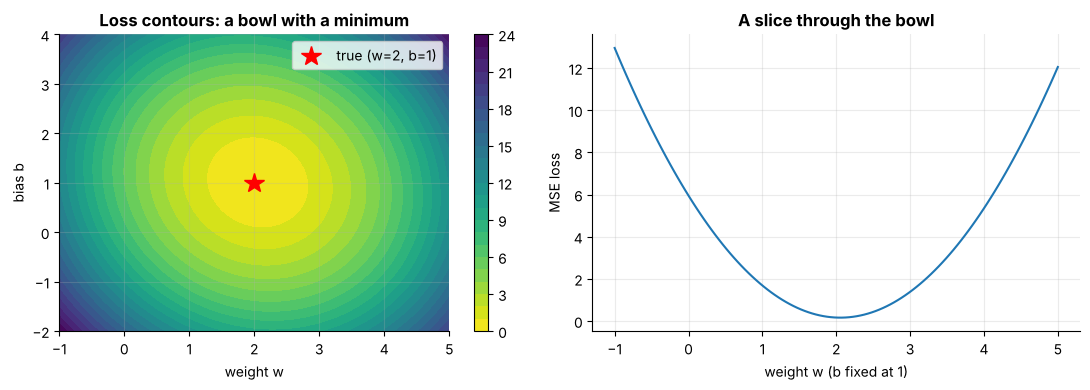

In [8]:
rng = np.random.default_rng(0)
x = rng.uniform(-2, 2, 50); y = 2.0 * x + 1.0 + rng.normal(0, 0.4, 50)      # truth: w=2, b=1
ws, bs = np.meshgrid(np.linspace(-1, 5, 120), np.linspace(-2, 4, 120))
loss = ((ws[..., None] * x + bs[..., None] - y) ** 2).mean(-1)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
cs = ax[0].contourf(ws, bs, loss, 25, cmap="viridis_r"); ax[0].plot(2, 1, "r*", ms=15, label="true (w=2, b=1)")
ax[0].set(xlabel="weight w", ylabel="bias b", title="Loss contours: a bowl with a minimum"); ax[0].legend(); plt.colorbar(cs, ax=ax[0])
ax[1].plot(ws[0], loss[np.argmin(np.abs(bs[:, 0] - 1)), :]); ax[1].set(xlabel="weight w (b fixed at 1)", ylabel="MSE loss", title="A slice through the bowl")
plt.tight_layout(); plt.show()

> 📝 **Note**: Real networks have millions of weights, so the landscape lives in millions of dimensions and has ridges, plateaus and saddle points, but the intuition *"walk downhill"* carries over. Next lesson we learn how to find the downhill direction efficiently.

---
## 🧭 7. Loss ≠ metric

* **Loss**: what the optimiser minimises. Must be differentiable. (cross-entropy, MSE)
* **Metric**: what *humans* care about and report. (accuracy, F1, MAE in KES, recall on diseased plants)

They usually move together but not always. Here two models both score 80 % accuracy, yet one is far more *confident when wrong*: cross-entropy tells them apart, accuracy can't:

In [9]:
y = np.array([1, 1, 1, 1, 0, 0, 0, 0, 1, 0])
model_a = np.array([.6, .6, .6, .6, .4, .4, .4, .4, .4, .6])      # right 80%, timid
model_b = np.array([.99, .99, .99, .99, .01, .01, .01, .01, .01, .99])  # right 80%, overconfident
bce = lambda y, p: -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))
for name, p in [("A (timid)", model_a), ("B (overconfident)", model_b)]:
    print(f"{name:20s} accuracy = {np.mean((p > .5) == y):.0%}   BCE loss = {bce(y, p):.3f}")

A (timid)            accuracy = 80%   BCE loss = 0.592
B (overconfident)    accuracy = 80%   BCE loss = 0.929


> 🇰🇪 **In the field**: For disease detection, *accuracy hides what matters*. Missing a diseased plant (false negative) can cost a farmer a harvest; a false alarm costs a pesticide spray. You'll choose metrics like **recall** and **per-class F1** in Projects 2–3.

---
# 🏋️ Practice problems
Work through these in order. Each problem has **hints** (open them one at a time: struggling a little is how learning happens!) and a **self-check cell** that tells you ✅ or ❌. Full solutions live in `../solutions/`.

*Difficulty:* ⭐ warm-up · ⭐⭐ standard · ⭐⭐⭐ challenge

---
### 🧩 Problem 3.1: MSE, MAE & Huber  &nbsp; `⭐`

Implement `mse(y_hat, y)`, `mae(y_hat, y)` and `huber(y_hat, y, delta=1.0)` (all return the **mean** over the samples).

<details><summary>💡 Hint 1</summary>

`np.mean((y_hat - y) ** 2)` is MSE.

</details>

<details><summary>💡 Hint 2</summary>

For Huber: compute `e = np.abs(y_hat - y)` then `np.where(e <= delta, 0.5*e**2, delta*(e - 0.5*delta))`.

</details>


In [ ]:
def mse(y_hat, y):
    pass
def mae(y_hat, y):
    pass
def huber(y_hat, y, delta=1.0):
    pass

In [ ]:
# ▶ self-check (run after you've written your answer)
yh, y = np.array([1., 2., 3., 10.]), np.array([1., 2., 4., 4.])
try:
    dl.check("MSE = 9.25", np.isclose(mse(yh, y), 9.25))
    dl.check("MAE = 1.75", np.isclose(mae(yh, y), 1.75))
    dl.check("Huber(δ=1) = 1.5", np.isclose(huber(yh, y), (0 + 0 + .5 + 5.5) / 4))
    dl.check("Huber is less outlier-sensitive than MSE", huber(yh, y) < mse(yh, y))
except Exception:
    dl.check("implement all three losses", False)

---
### 🧩 Problem 3.2: Binary cross-entropy  &nbsp; `⭐⭐`

Implement `bce(p, y, eps=1e-12)`. Clip probabilities into `[eps, 1-eps]` first so `log(0)` can never happen. Return the mean loss.

<details><summary>💡 Hint 1</summary>

`np.clip(p, eps, 1 - eps)`

</details>

<details><summary>💡 Hint 2</summary>

Formula: `-(y*log(p) + (1-y)*log(1-p))`, then `.mean()`.

</details>


In [ ]:
def bce(p, y, eps=1e-12):
    pass

In [ ]:
# ▶ self-check (run after you've written your answer)
try:
    dl.check("perfect predictions → loss ≈ 0", bce(np.array([1., 0.]), np.array([1, 0])) < 1e-9)
    dl.check("p=0.5 everywhere → ln 2", np.isclose(bce(np.full(4, .5), np.array([1, 0, 1, 0])), np.log(2)))
    dl.check("worked example 0.572 → 0.559", np.isclose(bce(np.array([0.572]), np.array([1])), 0.5586, atol=1e-3))
    dl.check("confidently wrong is finite but huge", 20 < bce(np.array([0.0]), np.array([1])) < 40)
except Exception:
    dl.check("implement bce", False)

---
### 🧩 Problem 3.3: Cross-entropy from logits  &nbsp; `⭐⭐`

Implement `ce_loss(logits, y)` for a batch: `logits` is `(m, k)`, `y` holds integer labels. Use the **log-sum-exp trick** so it works for logits like 1000.
Return the mean loss.

<details><summary>💡 Hint 1</summary>

`m = logits.max(1, keepdims=True)`, then `lse = m[:,0] + np.log(np.exp(logits - m).sum(1))`.

</details>

<details><summary>💡 Hint 2</summary>

The correct class's logit is `logits[np.arange(len(y)), y]`.

</details>

<details><summary>💡 Hint 3</summary>

Loss per example = `lse - correct_logit`.

</details>


In [ ]:
def ce_loss(logits, y):
    pass

In [ ]:
# ▶ self-check (run after you've written your answer)
logits = np.array([[2.0, 1.0, 0.1], [0.1, 0.2, 3.0]]); y = np.array([0, 2])
try:
    dl.check("matches textbook value", np.isclose(ce_loss(logits, y), 0.2633, atol=1e-3))
    dl.check("stable for huge logits", np.isfinite(ce_loss(np.array([[1000., 0, -1000]]), np.array([2]))))
    dl.check("uniform logits give ln k", np.isclose(ce_loss(np.zeros((5, 10)), np.zeros(5, int)), np.log(10)))
except Exception:
    dl.check("implement ce_loss", False)

---
### 🧩 Problem 3.4: Forward pass + loss of the irrigation network  &nbsp; `⭐⭐`

Using the network from Section 1 (weights are provided in the starter), write `predict_and_loss(x, y)` that returns a tuple `(y_hat, loss)`:
the sigmoid output and the BCE loss: for an input `x` of shape `(2,)` and a label `y`.
Then compute the result for `x = (3, 0.5)`, `y = 0`.

<details><summary>💡 Hint 1</summary>

Use `x @ W1 + b1`, ReLU, `@ W2 + b2`, sigmoid: exactly as in the worked example (vectors work as well as 1-row matrices).

</details>

<details><summary>💡 Hint 2</summary>

BCE for one example: `-(y*log(p)+(1-y)*log(1-p))`.

</details>


In [ ]:
W1 = np.array([[0.5, -0.4], [0.3, 0.8]]); b1 = np.array([0.1, -0.2])
W2 = np.array([0.7, -0.6]);               b2 = 0.05

def predict_and_loss(x, y):
    pass   # return y_hat, loss

In [ ]:
# ▶ self-check (run after you've written your answer)
res = predict_and_loss(np.array([1., 2.]), 1)
dl.check("worked example: ŷ≈0.572", res is not None and np.isclose(res[0], 0.572, atol=1e-3))
dl.check("worked example: loss≈0.559", res is not None and np.isclose(res[1], 0.5587, atol=1e-3))
res2 = predict_and_loss(np.array([3., 0.5]), 0)
dl.check("second example runs and loss > 0", res2 is not None and res2[1] > 0)

---
### 🧩 Problem 3.5: Initial-loss sanity check on real data  &nbsp; `⭐⭐`

Create a randomly initialised 784 → 64 → 10 network with **small** weights (`np.random.default_rng(0).normal(0, 0.01, ...)`, zero biases),
run MNIST images (first 1,000 training images, flattened) through it with ReLU, and compute the mean cross-entropy loss using the stable formula.
Store it in `initial_loss`. It should be close to ln 10 ≈ 2.30. *(This is the first thing real practitioners check!)*

<details><summary>💡 Hint 1</summary>

Load with `dl.load_mnist(n_train=1000, flatten=True)` → the first returned item is `x_train` of shape `(1000, 784)`.

</details>

<details><summary>💡 Hint 2</summary>

Forward: `h = np.maximum(0, x @ W1 + b1)`; `logits = h @ W2 + b2`.

</details>

<details><summary>💡 Hint 3</summary>

Reuse the log-sum-exp formula from the lesson.

</details>


In [ ]:
initial_loss = None   # compute it!

In [ ]:
# ▶ self-check (run after you've written your answer)
dl.check("initial loss is close to ln(10)=2.303", initial_loss is not None and abs(initial_loss - np.log(10)) < 0.1,
         "if you got ~50 or ~0.01 something is off: check your normalisation / formula")

---
## 🏁 Key takeaways
- ✅ **Forward propagation** = push inputs through `Z = AW + b → A = f(Z)` layer by layer; the result is a prediction.
- ✅ A **loss** turns prediction quality into *one differentiable number*; training minimises its average.
- ✅ **Regression:** MSE (punishes big errors), MAE (robust), Huber (compromise). **Classification:** cross-entropy = *−ln(probability given to the truth)*.
- ✅ Compute cross-entropy **from logits** with the log-sum-exp trick; in PyTorch pass raw logits + integer labels to `CrossEntropyLoss`.
- ✅ Cross-entropy beats MSE for classification because its gradient *doesn't vanish* when the model is confidently wrong.
- ✅ Sanity check: **initial loss ≈ ln(k)**. A **metric** (accuracy, F1, KES-error) is what we report; the **loss** is what we optimise.

---
## 🧠 Check your understanding
Try to answer *out loud* before you open the answer. If you can explain it to a friend, you own it.
**Q1.** The true class gets probability 0.25 from a classifier. What's the cross-entropy loss?

<details><summary>Answer</summary>

$-\ln 0.25 = \ln 4 \approx 1.386$.

</details>

**Q2.** Why do we typically *not* optimise accuracy directly?

<details><summary>Answer</summary>

Accuracy is piecewise constant: a tiny weight change either doesn't change any prediction (zero gradient) or flips one abruptly. Gradient descent needs a smooth signal.

</details>

**Q3.** You train a 5-class model and the first-iteration loss is 0.02. What might be wrong?

<details><summary>Answer</summary>

Expected ≈ ln 5 ≈ 1.61. A near-zero loss suggests label leakage, a trivial dataset, or a bug (e.g. computing loss on the wrong tensors).

</details>

**Q4.** When would you prefer MAE over MSE?

<details><summary>Answer</summary>

When the data contain outliers you don't want to dominate training, or when you want an error that's directly interpretable (e.g. 'off by 300 KES on average').

</details>

---
## 📚 Go deeper (optional)
- Goodfellow, Bengio & Courville: *Deep Learning* (free online), §3.13 *Information theory* & §6.2 *Gradient-based learning*
- Chris Olah (*Visual Information Theory* (colah.github.io)) the best explanation of cross-entropy
- Karpathy: *A Recipe for Training Neural Networks*: 'verify loss @ init'

---
⬅️ Previous: [02 · Layers, Weights & Activation Functions](02_layers_and_activations.ipynb) &nbsp;|&nbsp; Next: [04 · Gradient Descent & Backpropagation](04_gradient_descent_backprop.ipynb) ➡️